# Background

- **Author**: 楊喬茵（AI 協助：Claude Code，Claude Opus 5.5）
- **Created At**: 2026-11-14
- **Research Motivation and Context (why are we interested in the findings?)：**
  本組階段一要依候選人背景分群（見 [proposal](../report/DSSI2026-group-3.md) 1.4 節）。許以琳的 [candidate_cluster_all_g6v2.ipynb](candidate_cluster_all_g6v2.ipynb) 以 Gower 距離＋PAM 分群，但政黨與學歷都當名目類別：國民黨與民進黨的距離，和民進黨與時代力量的距離同樣是 1。本 notebook 是**敏感度版本**，依楊喬茵 2026-11-14 的設定改變距離定義：
  - **政黨改用藍綠光譜**：依登記推薦政黨放在 0（純綠）到 1（純藍）的光譜上，無黨籍與難歸類小黨另成一類，距離見下方表 3。
  - **年齡與學歷保留順序**：年齡用 <40／40–49／50–59／60+ 四組，相鄰組別的距離小於相隔較遠的組別；學歷依楊喬茵 2026-11-14 決定給分數大學以下 0、大學 0.7、研究所 1，即大學與研究所較接近。
  - 其餘（G2 性別、G5 首次參選、G6 政治家族）與許以琳版本相同。
  - 輸入：`data/processed/candidates_scope_g1_g6_20261110.csv`（許以琳以 [apply_g6_teammate_20261110.ipynb](../data/code/apply_g6_teammate_20261110.ipynb) 產生，G6 已採張睿庠有來源的親屬資料；該 notebook 開頭即為資料說明）。267 人：全部縣市長與臺北、高雄市議員。
- **Main Findings and Takeaways：**
  - 依與許以琳版本相同的手肘規則，本版本也選 **k = 3**，三群 96／86／85 人，平均 silhouette 0.255。
  - 三群為：第 1 群「國民黨為主的曾參選男性」（國民黨 66%、民進黨 25%、男性 82%、研究所 77%，代表人物吳宗憲）；第 2 群「女性或政治家族、民進黨為主」（女性 81%、政治家族 73%、民進黨 58%，代表人物鍾佩玲）；第 3 群「非藍綠」（無黨籍／難歸類 89%、縣市長 46%、研究所僅 40%，代表人物蘇輝湟）。
  - 這個 k = 3 結果對政黨與學歷的細部設定不敏感：在本 notebook 開發過程中，政黨先用四個陣營、學歷先用等距（0／0.5／1），之後改成目前的光譜位置與學歷 0／0.7／1，k = 3 的各群人數、組成與代表人物都沒有改變。
  - 和許以琳版本相比（ARI 0.568）：「女性或政治家族」群幾乎相同（86 人中 81 人重疊）；主要差別是有 34 位曾參選、平均 59 歲、以男性為主的無黨籍或小黨候選人，從「男性國民黨為主」群移到「非藍綠」群。因此第 3 群的性質從許以琳版本的「無黨籍素人」（首次參選 71%）變成「非藍綠」（首次參選 38%）；k = 4 時這群再分成「非藍綠曾參選」（53 人，首次參選 0%）與「首次參選」（46 人，首次參選 100%，其中無黨籍／難歸類 65%、民進黨 17%、國民黨 9%）。
  - 穩定度略高於許以琳基準：80% 抽樣重跑 50 次的平均 ARI，本版本 k = 3 為 0.692（第 5 百分位 0.300），同一組抽樣下許以琳基準為 0.643（0.136）；年齡改用實際歲數的敏感度版本最高，為 0.768。三者都仍屬中等，少數抽樣會讓分群明顯改變。
  - 年齡用四組或實際歲數，全樣本分群幾乎相同（ARI 0.966）。
  - **權重敏感度**：本版本中政黨占兩兩平均距離 25.8%、學歷只占 10.5%（附表 A）。改成「各變數實際貢獻相等」後，手肘仍是 k = 3（131／83／53 人），穩定度最高（ARI 0.781）；「女性或政治家族」群仍在（83 人，與本版本 77 人重疊），但「非藍綠」群消失，第 3 群改為「首次參選」（53 人，首次參選 100%，無黨籍／難歸類 57%、民進黨 23%），其餘曾參選者併成一大群（131 人，國民黨 43%、無黨籍／難歸類 31%）。與本版本 k = 3 的 ARI 只有 0.431。也就是說，「女性或政治家族」群不依賴權重，「非藍綠」群則主要來自政黨的較大權重。
- **Future Direction：**
  - 本 notebook 是距離定義的敏感度版本，是否取代許以琳版本當主分析，需與許以琳及全組討論。
  - 政黨光譜位置（泛綠小黨 0.2、民眾黨 0.6、泛藍小黨 0.8）與學歷分數（大學 0.7）都是判斷值；報告須寫出各小黨歸入泛綠或泛藍的依據（例如結盟或選舉合作紀錄）。
  - 主分析要用「名義等權重」（政黨實際占約 26%）還是「各變數實際貢獻相等」，需組內決定：前者的第 3 群是「非藍綠」，後者是「首次參選」。若研究重點是 H5 黨派，前者較貼近；若希望各背景變數同等重要，後者較穩（0.781）。
  - 年齡改用實際歲數的版本穩定度較高（0.768），可考慮作為主設定，描述各群時再用年齡組呈現。

In [1]:
from pathlib import Path
import hashlib
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

for _font in ["Microsoft JhengHei", "Noto Sans CJK TC", "PingFang TC", "Heiti TC"]:
    if any(f.name == _font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = _font
        break
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
SEED = 20261114

In [2]:
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("找不到含 AGENTS.md 與 templates/ 的專案根目錄")


ROOT = find_project_root()
INPUT_PATH = "data/processed/candidates_scope_g1_g6_20261110.csv"
EXPECTED_SHA256 = {  # PROJECT.md Data Artifacts 登記值（CRLF 位元組）；另接受換行統一為 LF 的同內容版本
    "ff2a7214ccaeb86a2ea2b5caf1883cb07aa7f37454505d76f221b6f6ac0c7ea0",
}
path = ROOT / INPUT_PATH
if not path.is_file():
    raise FileNotFoundError(INPUT_PATH)
raw_bytes = path.read_bytes()
digest = hashlib.sha256(raw_bytes).hexdigest()
if digest not in EXPECTED_SHA256:
    crlf = hashlib.sha256(raw_bytes.replace(b"\r\n", b"\n").replace(b"\n", b"\r\n")).hexdigest()
    if crlf not in EXPECTED_SHA256:
        raise ValueError(f"{INPUT_PATH} 內容與已登記版本不同：{digest}")

df = pd.read_csv(path, dtype=str, encoding="utf-8-sig")
REQUIRED = ["candidate_key", "candidate_name", "county_city", "office_type", "G1_age_2026_minus_birth_year",
            "G2_sex", "G3_education_level", "G4_party", "party_registration_raw",
            "G5_first_time_any_elected_office", "G6_political_family"]
assert not set(REQUIRED) - set(df.columns)
assert df["candidate_key"].is_unique and len(df) == 267
assert df[REQUIRED].notna().all().all()

# 年齡分組（順序 0–3）與學歷（順序 0–2）
df["age"] = pd.to_numeric(df["G1_age_2026_minus_birth_year"], errors="raise")
AGE_LABELS = ["<40", "40–49", "50–59", "60+"]
df["age_rank"] = pd.cut(df["age"], bins=[0, 39, 49, 59, 200], labels=False).astype(int)
df["age_group"] = df["age_rank"].map(dict(enumerate(AGE_LABELS)))
EDU_LABELS = ["大學以下", "大學", "研究所"]
EDU_SCORE = {"大學以下": 0.0, "大學": 0.7, "研究所": 1.0}  # 楊喬茵 2026-11-14 決定：大學與研究所較接近
df["edu_rank"] = df["G3_education_level"].map(EDU_SCORE)
assert df["edu_rank"].notna().all()

# 政黨藍綠光譜位置：楊喬茵 2026-11-14 決定（0 = 純綠、1 = 純藍；無黨籍與難歸類小黨不在光譜上）
CAMP_OF = {"民主進步黨": "民進黨", "中國國民黨": "國民黨", "台灣民眾黨": "民眾黨",
           "時代力量": "泛綠小黨", "台灣基進": "泛綠小黨", "台聯黨": "泛綠小黨", "台灣綠黨": "泛綠小黨", "社會民主黨": "泛綠小黨",
           "新黨": "泛藍小黨", "勞動黨": "泛藍小黨"}
CAMPS = ["民進黨", "泛綠小黨", "民眾黨", "泛藍小黨", "國民黨", "無黨籍／難歸類"]
POSITION = {"民進黨": 0.0, "泛綠小黨": 0.2, "民眾黨": 0.6, "泛藍小黨": 0.8, "國民黨": 1.0}
df["camp"] = df["party_registration_raw"].map(CAMP_OF).fillna("無黨籍／難歸類")
assert set(df.loc[df["G4_party"] == "國民黨", "camp"]) == {"國民黨"}
assert set(df.loc[df["G4_party"] == "民進黨", "camp"]) == {"民進黨"}
assert set(df.loc[df["G4_party"] == "無黨籍／未經政黨推薦", "camp"]) == {"無黨籍／難歸類"}

df["sex"] = df["G2_sex"]
df["first_time"] = df["G5_first_time_any_elected_office"].map({"1": "首次參選", "0": "曾參選"})
df["political_family"] = df["G6_political_family"].map({"1": "政治家族", "0": "非政治家族"})
df["office"] = np.where(df["office_type"] == "直轄市議員", "議員", "縣市長")

print(f"分析樣本：{len(df)} 人；輸入檔 {INPUT_PATH}（SHA-256 已核對）")
print("各陣營包含的登記政黨：")
display(df.groupby(["camp", "party_registration_raw"]).size().rename("人數").to_frame())
df[["candidate_name", "county_city", "office", "age", "age_group", "sex", "G3_education_level",
    "party_registration_raw", "camp", "first_time", "political_family"]].head(10)

分析樣本：267 人；輸入檔 data/processed/candidates_scope_g1_g6_20261110.csv（SHA-256 已核對）
各陣營包含的登記政黨：


人數
camp    party_registration_raw    
國民黨     中國國民黨                   85
民眾黨     台灣民眾黨                    8
民進黨     民主進步黨                   80
泛綠小黨    台灣基進                     2
        台灣綠黨                     1
        台聯黨                      2
        時代力量                     2
        社會民主黨                    1
泛藍小黨    勞動黨                      1
        新黨                       3
無黨籍／難歸類 三勢團結促進聯盟                 1
        台灣工黨                     1
        台灣麻將最大黨                  1
        司法改革黨                    2
        司法正義黨                    1
        天宙和平統一家庭黨                1
        小民參政歐巴桑聯盟                2
        左翼聯盟                     1
        永久和平自然法                  1
        無                       69
        臺灣SoR無法黨                 2

,candidate_name,county_city,office,age,age_group,sex,G3_education_level,party_registration_raw,camp,first_time,political_family
0,郭璽,臺北市,縣市長,68,60+,男,大學,台灣麻將最大黨,無黨籍／難歸類,曾參選,非政治家族
1,沈伯洋,臺北市,縣市長,44,40–49,男,研究所,民主進步黨,民進黨,曾參選,政治家族
2,蕭文乾,臺北市,縣市長,52,50–59,男,研究所,臺灣SoR無法黨,無黨籍／難歸類,曾參選,非政治家族
3,唐新民,臺北市,縣市長,76,60+,男,研究所,三勢團結促進聯盟,無黨籍／難歸類,曾參選,非政治家族
4,蔣萬安,臺北市,縣市長,48,40–49,男,研究所,中國國民黨,國民黨,曾參選,政治家族
5,林志成,臺北市,縣市長,61,60+,男,研究所,無,無黨籍／難歸類,曾參選,非政治家族
6,蘇巧慧,新北市,縣市長,50,50–59,女,研究所,民主進步黨,民進黨,曾參選,政治家族
7,李四川,新北市,縣市長,68,60+,男,研究所,中國國民黨,國民黨,首次參選,非政治家族
8,蘇輝湟,新北市,縣市長,50,50–59,男,大學,無,無黨籍／難歸類,曾參選,非政治家族
9,張善政,桃園市,縣市長,72,60+,男,研究所,中國國民黨,國民黨,曾參選,非政治家族


In [3]:
VAR_LABELS = {"age": "年齡（2026 減出生年）", "age_group": "年齡組", "sex": "性別", "G3_education_level": "學歷",
              "G4_party": "政黨（原五類）", "camp": "政黨陣營", "first_time": "首次參選任何民選公職",
              "political_family": "政治家族背景", "office": "公職類別"}
a = df["age"]
print(f"表 1　數值變數摘要（N = {len(df)}）")
display(pd.DataFrame({"變數": [VAR_LABELS["age"]], "N": [a.notna().sum()], "缺值": [a.isna().sum()],
                      "平均": [a.mean()], "標準差": [a.std()], "最小": [a.min()], "P25": [a.quantile(.25)],
                      "中位數": [a.median()], "P75": [a.quantile(.75)], "最大": [a.max()]}).round(2))
ORDER = {"age_group": AGE_LABELS, "G3_education_level": EDU_LABELS,
         "camp": CAMPS}
rows = []
for col in ["age_group", "sex", "G3_education_level", "G4_party", "camp", "first_time", "political_family", "office"]:
    s = df[col]; n = s.notna().sum()
    vc = s.value_counts()
    if col in ORDER:
        vc = vc.reindex(ORDER[col])
    for cat, c in vc.head(10).items():
        rows.append({"變數": VAR_LABELS[col], "N": n, "缺值": s.isna().sum(), "類別": cat,
                     "人數": int(c), "百分比": round(100 * c / n, 1)})
print(f"表 2　類別變數摘要（N = {len(df)}；百分比分母為該變數非缺值人數）")
pd.DataFrame(rows)

表 1　數值變數摘要（N = 267）


,變數,N,缺值,平均,標準差,最小,P25,中位數,P75,最大
0,年齡（2026 減出生年）,267,0,52.02,11.62,24,43.5,52.0,61.0,83


表 2　類別變數摘要（N = 267；百分比分母為該變數非缺值人數）


,變數,N,缺值,類別,人數,百分比
0,年齡組,267,0,<40,43,16.1
1,年齡組,267,0,40–49,74,27.7
2,年齡組,267,0,50–59,74,27.7
3,年齡組,267,0,60+,76,28.5
4,性別,267,0,男,167,62.5
5,性別,267,0,女,100,37.5
6,學歷,267,0,大學以下,28,10.5
7,學歷,267,0,大學,70,26.2
8,學歷,267,0,研究所,169,63.3
9,政黨（原五類）,267,0,國民黨,85,31.8


### The actual analysis starts below

**距離定義**（Gower 距離：6 個變數各自算 0–1 的差距，再取平均）

| 變數 | 本版本（光譜＋順序） | 許以琳版本（基準） |
|---|---|---|
| G1 年齡 | 四組順序：相差幾組 ÷ 3（例如 40–49 與 50–59 = 0.33） | 實際歲數差 ÷ 全距 |
| G2 性別 | 相同 0、不同 1 | 同左 |
| G3 學歷 | 順序分數：大學以下 0、大學 0.7、研究所 1，距離為分數差（大學 vs 研究所 = 0.3、大學以下 vs 大學 = 0.7、大學以下 vs 研究所 = 1） | 相同 0、不同 1 |
| G4 政黨 | 藍綠光譜位置差（表 3） | 五類，相同 0、不同 1 |
| G5、G6 | 相同 0、不同 1 | 同左 |

**政黨距離（表 3）**：依楊喬茵 2026-11-14 決定，把政黨放在 0（純綠）到 1（純藍）的藍綠光譜上，兩黨距離為位置差：民進黨 0、泛綠小黨（時代力量、台灣基進、台聯、台灣綠黨、社會民主黨）0.2、民眾黨 0.6（偏藍的中間，距國民黨 0.4）、泛藍小黨（新黨、勞動黨）0.8、國民黨 1。無黨籍與難放上藍綠光譜的小黨（司法改革黨、臺灣SoR無法黨等）不在光譜上，與任何政黨的距離為 1，彼此之間為 0。

**權重敏感度**：6 個變數名義上等權重，但實際對距離的貢獻不同（見附表 A）。另做一個「各變數實際貢獻相等」的版本：每個變數的差距先除以該變數的兩兩平均差距，再取平均，使 6 個變數對平均距離的貢獻都是 1/6。

**選群數**：與許以琳版本相同，k = 1–10 各跑 PAM，以總成本曲線的「首尾連線」找手肘（曲線離首尾連線最遠的 k），並列平均 silhouette 與最小群人數。

In [4]:
def party_distance(a, b):
    if a in POSITION and b in POSITION:
        return abs(POSITION[a] - POSITION[b])
    return 0.0 if (a not in POSITION and b not in POSITION) else 1.0

PARTY_DIST = pd.DataFrame([[party_distance(a, b) for b in CAMPS] for a in CAMPS], index=CAMPS, columns=CAMPS)
print("表 3　政黨之間的距離（光譜位置：民進黨 0、泛綠小黨 0.2、民眾黨 0.6、泛藍小黨 0.8、國民黨 1）")
display(PARTY_DIST.round(2))

def nominal(s):
    v = s.to_numpy()
    return (v[:, None] != v[None, :]).astype(float)

def ordinal(x, span):
    v = x.to_numpy(float)
    return np.abs(v[:, None] - v[None, :]) / span

common = nominal(df["sex"]) + nominal(df["first_time"]) + nominal(df["political_family"])
party_spectrum = PARTY_DIST.loc[df["camp"], df["camp"]].to_numpy()
age_range = df["age"].max() - df["age"].min()

shared = {"性別": nominal(df["sex"]), "首次參選": nominal(df["first_time"]), "政治家族": nominal(df["political_family"])}
PARTS = {
    "本版本（光譜＋順序）": {"年齡": ordinal(df["age_rank"], 3), "學歷": ordinal(df["edu_rank"], 1), "政黨": party_spectrum, **shared},
    "敏感度：年齡改實際歲數": {"年齡": ordinal(df["age"], age_range), "學歷": ordinal(df["edu_rank"], 1), "政黨": party_spectrum, **shared},
    "許以琳基準（名目類別）": {"年齡": ordinal(df["age"], age_range), "學歷": nominal(df["G3_education_level"]),
                       "政黨": nominal(df["G4_party"]), **shared},
}
IU = np.triu_indices(len(df), 1)
# 敏感度：各變數實際貢獻相等——每個變數先除以自己的兩兩平均差距，再取平均（楊喬茵 2026-11-14 要求試做）
PARTS["敏感度：各變數實際貢獻相等"] = {v: m / m[IU].mean() for v, m in PARTS["本版本（光譜＋順序）"].items()}
DIST = {name: sum(parts.values()) / 6 for name, parts in PARTS.items()}
D_MAIN, D_AGE_CONT = DIST["本版本（光譜＋順序）"], DIST["敏感度：年齡改實際歲數"]
D_BASE, D_EQ = DIST["許以琳基準（名目類別）"], DIST["敏感度：各變數實際貢獻相等"]
for name, D in DIST.items():
    assert np.allclose(D, D.T) and np.allclose(np.diag(D), 0)
    print(f"{name}：兩兩平均距離 {D[IU].mean():.3f}，距離值種類 {len(np.unique(D.round(9)))}")

share = pd.DataFrame({name: {v: m[IU].mean() for v, m in parts.items()} for name, parts in PARTS.items()})
share = (share / share.sum() * 100).round(1)
print("附表 A　各變數占兩兩平均距離的比例（%；名義上各 1/6 = 16.7%）")
display(share)

表 3　政黨之間的距離（光譜位置：民進黨 0、泛綠小黨 0.2、民眾黨 0.6、泛藍小黨 0.8、國民黨 1）


,民進黨,泛綠小黨,民眾黨,泛藍小黨,國民黨,無黨籍／難歸類
民進黨,0.0,0.2,0.6,0.8,1.0,1.0
泛綠小黨,0.2,0.0,0.4,0.6,0.8,1.0
民眾黨,0.6,0.4,0.0,0.2,0.4,1.0
泛藍小黨,0.8,0.6,0.2,0.0,0.2,1.0
國民黨,1.0,0.8,0.4,0.2,0.0,1.0
無黨籍／難歸類,1.0,1.0,1.0,1.0,1.0,0.0


本版本（光譜＋順序）：兩兩平均距離 0.431，距離值種類 146


敏感度：年齡改實際歲數：兩兩平均距離 0.403，距離值種類 1625
許以琳基準（名目類別）：兩兩平均距離 0.457，距離值種類 310
敏感度：各變數實際貢獻相等：兩兩平均距離 1.000，距離值種類 637
附表 A　各變數占兩兩平均距離的比例（%；名義上各 1/6 = 16.7%）


,本版本（光譜＋順序）,敏感度：年齡改實際歲數,許以琳基準（名目類別）,敏感度：各變數實際貢獻相等
年齡,15.1,9.3,8.2,16.7
學歷,10.5,11.2,19.0,16.7
政黨,25.8,27.5,26.8,16.7
性別,18.2,19.4,17.2,16.7
首次參選,13.4,14.3,12.6,16.7
政治家族,17.0,18.2,16.1,16.7


In [5]:
def pam(D, k):
    # BUILD：先選總距離最小者，再逐一加入讓總成本下降最多的人；SWAP：嘗試代表與非代表互換，直到總成本不再下降
    n = len(D)
    med = [int(D.sum(axis=1).argmin())]
    while len(med) < k:
        dmin = D[:, med].min(axis=1)
        gain = np.maximum(dmin[None, :] - D, 0).sum(axis=1)
        gain[med] = -1
        med.append(int(gain.argmax()))
    cost = D[:, med].min(axis=1).sum()
    improved = True
    while improved:
        improved = False
        for i in range(k):
            for h in range(n):
                if h in med:
                    continue
                trial = med.copy(); trial[i] = h
                c = D[:, trial].min(axis=1).sum()
                if c < cost - 1e-12:
                    med, cost, improved = trial, c, True
    return D[:, med].argmin(axis=1), med, cost


def silhouette(D, lab):
    s = np.zeros(len(lab))
    for i in range(len(lab)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a_i = D[i, same].sum() / (same.sum() - 1)
        b_i = min(D[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
        s[i] = (b_i - a_i) / max(a_i, b_i) if max(a_i, b_i) > 0 else 0
    return s.mean()


def ari(a, b):
    tab = pd.crosstab(np.asarray(a), np.asarray(b)).to_numpy()
    s = sum(comb(int(x), 2) for x in tab.ravel())
    ra = sum(comb(int(x), 2) for x in tab.sum(axis=1))
    cb = sum(comb(int(x), 2) for x in tab.sum(axis=0))
    exp = ra * cb / comb(int(tab.sum()), 2)
    return (s - exp) / ((ra + cb) / 2 - exp)


def relabel(lab):
    order = pd.Series(lab).value_counts().index  # 依人數由大到小編為第 1、2、… 群
    m = {old: new for new, old in enumerate(order, start=1)}
    return np.array([m[x] for x in lab])


def choose_k(D):
    rows, fits = [], {}
    for k in range(1, 11):
        lab, med, cost = pam(D, k)
        fits[k] = (relabel(lab), med, lab)
        rows.append({"k": k, "總成本": cost, "silhouette": np.nan if k == 1 else silhouette(D, lab),
                     "最小群人數": int(np.bincount(lab).min())})
    tab = pd.DataFrame(rows).set_index("k")
    w = tab["總成本"].to_numpy()
    ks = np.arange(1, 11)
    chord = w[0] + (w[-1] - w[0]) / 9 * (ks - 1)
    tab["離首尾連線"] = chord - w
    tab["成本減少（%）"] = (-tab["總成本"].pct_change() * 100)
    return tab, int(ks[(chord - w).argmax()]), fits


tab_main, K_MAIN, fits_main = choose_k(D_MAIN)
tab_cont, K_CONT, fits_cont = choose_k(D_AGE_CONT)
tab_base, K_BASE, fits_base = choose_k(D_BASE)
tab_eq, K_EQ, fits_eq = choose_k(D_EQ)
print(f"表 4　本版本：k = 1–10 的 PAM 總成本、silhouette 與最小群（N = {len(df)}）")
display(tab_main.round(3))
print(f"手肘切點：本版本 k = {K_MAIN}；敏感度（年齡實際歲數）k = {K_CONT}；許以琳基準 k = {K_BASE}；"
      f"敏感度（各變數實際貢獻相等）k = {K_EQ}")

表 4　本版本：k = 1–10 的 PAM 總成本、silhouette 與最小群（N = 267）


,總成本,silhouette,最小群人數,離首尾連線,成本減少（%）
k,,,,,
1,91.011,NaN,267,0.000,NaN
2,67.267,0.309,110,16.833,26.090
3,55.883,0.255,85,21.306,16.923
4,49.706,0.256,46,20.572,11.055
5,44.217,0.300,39,19.150,11.043
6,39.811,0.303,38,16.644,9.964
7,36.911,0.318,26,12.633,7.284
8,33.944,0.336,19,8.689,8.037
9,31.400,0.376,18,4.322,7.496


手肘切點：本版本 k = 3；敏感度（年齡實際歲數）k = 3；許以琳基準 k = 3；敏感度（各變數實際貢獻相等）k = 3


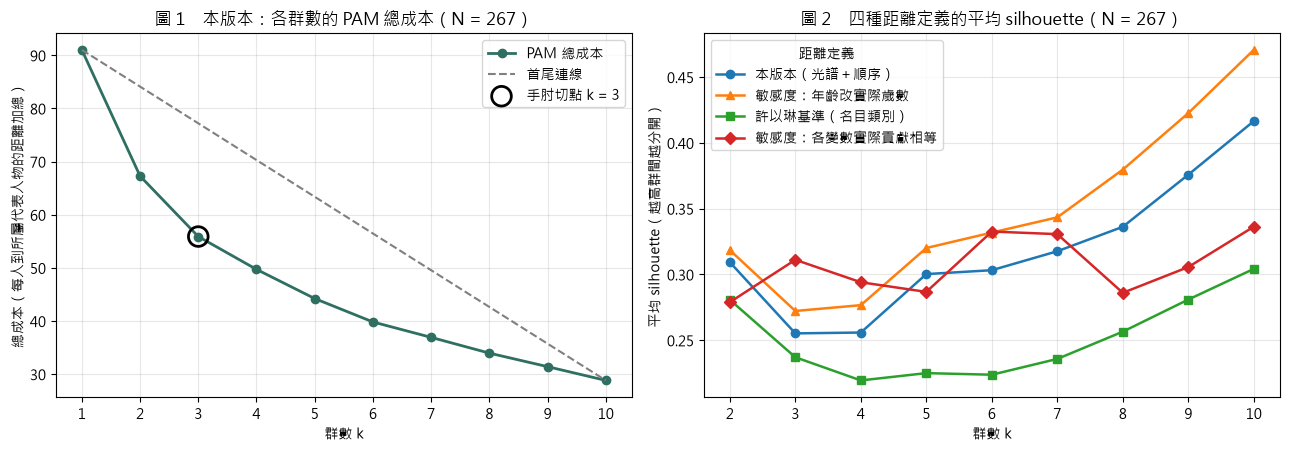

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ks = tab_main.index.to_numpy()
w = tab_main["總成本"].to_numpy()
ax = axes[0]
ax.plot(ks, w, marker="o", color="#2f6f62", linewidth=2, label="PAM 總成本")
ax.plot([1, 10], [w[0], w[-1]], linestyle="--", color="grey", label="首尾連線")
ax.scatter([K_MAIN], [tab_main.loc[K_MAIN, "總成本"]], s=200, facecolors="none", edgecolors="black",
           linewidths=2, zorder=4, label=f"手肘切點 k = {K_MAIN}")
ax.set_title(f"圖 1　本版本：各群數的 PAM 總成本（N = {len(df)}）")
ax.set_xlabel("群數 k"); ax.set_ylabel("總成本（每人到所屬代表人物的距離加總）")
ax.set_xticks(ks); ax.legend(); ax.grid(alpha=.3)
ax = axes[1]
for tab, label, marker in [(tab_main, "本版本（光譜＋順序）", "o"), (tab_cont, "敏感度：年齡改實際歲數", "^"),
                           (tab_base, "許以琳基準（名目類別）", "s"), (tab_eq, "敏感度：各變數實際貢獻相等", "D")]:
    s = tab["silhouette"].dropna()
    ax.plot(s.index, s.values, marker=marker, linewidth=1.8, label=label)
ax.set_title(f"圖 2　四種距離定義的平均 silhouette（N = {len(df)}）")
ax.set_xlabel("群數 k"); ax.set_ylabel("平均 silhouette（越高群間越分開）")
ax.set_xticks(range(2, 11)); ax.legend(title="距離定義"); ax.grid(alpha=.3)
fig.tight_layout()
plt.show()

In [7]:
def describe(g):
    out = {"人數": len(g), "平均年齡": g["age"].mean()}
    for v in AGE_LABELS:
        out[f"年齡 {v}（%）"] = 100 * (g["age_group"] == v).mean()
    out["女性（%）"] = 100 * (g["sex"] == "女").mean()
    for v in EDU_LABELS:
        out[f"學歷：{v}（%）"] = 100 * (g["G3_education_level"] == v).mean()
    for v in CAMPS:
        out[f"陣營：{v}（%）"] = 100 * (g["camp"] == v).mean()
    out["首次參選（%）"] = 100 * (g["first_time"] == "首次參選").mean()
    out["政治家族（%）"] = 100 * (g["political_family"] == "政治家族").mean()
    out["縣市長（%）"] = 100 * (g["office"] == "縣市長").mean()
    return out

MED_COLS = ["candidate_name", "office_type", "county_city", "age", "sex", "G3_education_level",
            "party_registration_raw", "camp", "first_time", "political_family"]
versions = [K_MAIN] + ([4] if K_MAIN != 4 else [])
for k in versions:
    lab, med, raw_lab = fits_main[k]
    df["_c"] = lab
    prof = pd.DataFrame({f"第 {c} 群": describe(g) for c, g in df.groupby("_c")})
    prof["全樣本"] = pd.Series(describe(df))
    print(f"表 {5 if k == K_MAIN else 6}　本版本 PAM k = {k} 各群特徵（N = {len(df)}；百分比分母為該群人數）")
    display(prof.round(1))
    mt = df.iloc[med][MED_COLS].copy()
    mt.insert(0, "群別", [f"第 {lab[i]} 群" for i in med])
    print(f"　k = {k} 各群代表人物（medoid）")
    display(mt.sort_values("群別").set_index("群別"))
df = df.drop(columns="_c")
df["cluster"] = fits_main[K_MAIN][0]

表 5　本版本 PAM k = 3 各群特徵（N = 267；百分比分母為該群人數）


,第 1 群,第 2 群,第 3 群,全樣本
人數,96.0,86.0,85.0,267.0
平均年齡,53.0,47.6,55.4,52.0
年齡 <40（%）,13.5,20.9,14.1,16.1
年齡 40–49（%）,22.9,40.7,20.0,27.7
年齡 50–59（%）,34.4,24.4,23.5,27.7
年齡 60+（%）,29.2,14.0,42.4,28.5
女性（%）,17.7,81.4,15.3,37.5
學歷：大學以下（%）,4.2,5.8,22.4,10.5
學歷：大學（%）,18.8,23.3,37.6,26.2
學歷：研究所（%）,77.1,70.9,40.0,63.3


　k = 3 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,G3_education_level,party_registration_raw,camp,first_time,political_family
群別,,,,,,,,,,
第 1 群,吳宗憲,縣（市）長,宜蘭縣,55,男,研究所,中國國民黨,國民黨,曾參選,非政治家族
第 2 群,鍾佩玲,直轄市議員,臺北市,47,女,研究所,民主進步黨,民進黨,曾參選,政治家族
第 3 群,蘇輝湟,直轄市長,新北市,50,男,大學,無,無黨籍／難歸類,曾參選,非政治家族


表 6　本版本 PAM k = 4 各群特徵（N = 267；百分比分母為該群人數）


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,85.0,83.0,53.0,46.0,267.0
平均年齡,54.1,47.8,56.8,50.1,52.0
年齡 <40（%）,8.2,20.5,7.5,32.6,16.1
年齡 40–49（%）,24.7,39.8,20.8,19.6,27.7
年齡 50–59（%）,35.3,25.3,28.3,17.4,27.7
年齡 60+（%）,31.8,14.5,43.4,30.4,28.5
女性（%）,20.0,83.1,11.3,17.4,37.5
學歷：大學以下（%）,4.7,6.0,18.9,19.6,10.5
學歷：大學（%）,18.8,20.5,41.5,32.6,26.2
學歷：研究所（%）,76.5,73.5,39.6,47.8,63.3


　k = 4 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,G3_education_level,party_registration_raw,camp,first_time,political_family
群別,,,,,,,,,,
第 1 群,吳宗憲,縣（市）長,宜蘭縣,55,男,研究所,中國國民黨,國民黨,曾參選,非政治家族
第 2 群,鍾佩玲,直轄市議員,臺北市,47,女,研究所,民主進步黨,民進黨,曾參選,政治家族
第 3 群,蘇輝湟,直轄市長,新北市,50,男,大學,無,無黨籍／難歸類,曾參選,非政治家族
第 4 群,李吳穎智,縣（市）長,臺東縣,47,男,大學,無,無黨籍／難歸類,首次參選,非政治家族


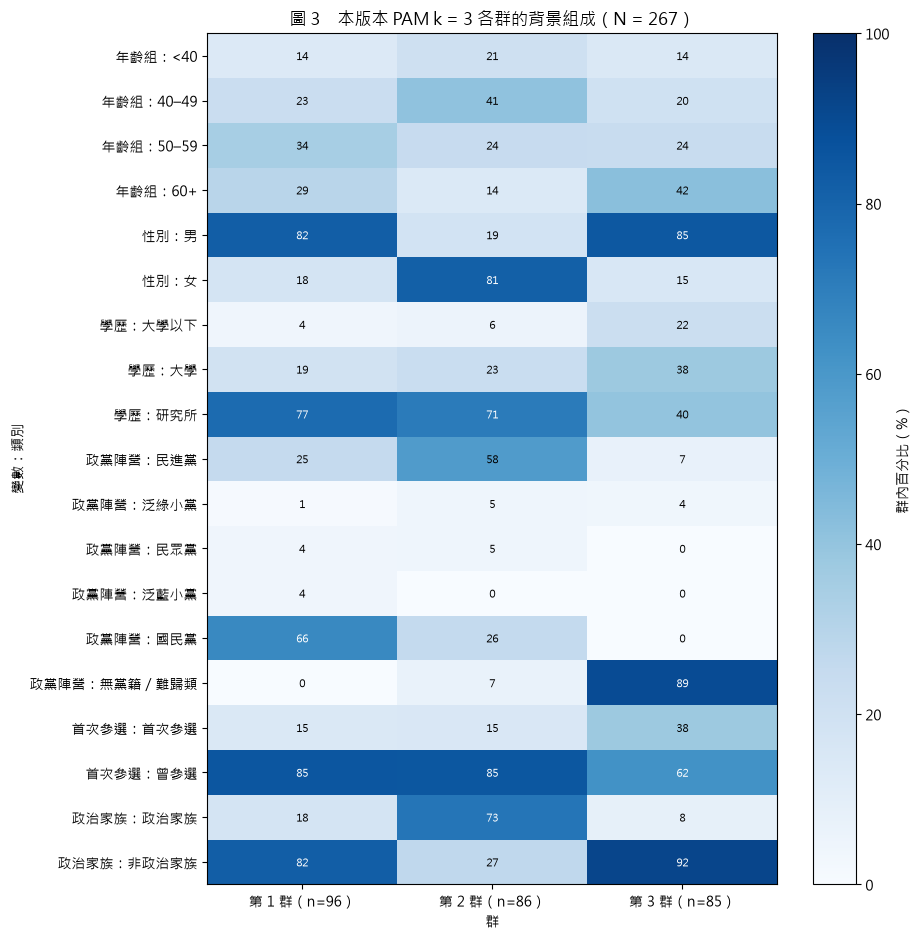

In [8]:
heat_rows = {}
for col, cats, label in [("age_group", AGE_LABELS, "年齡組"), ("sex", ["男", "女"], "性別"),
                         ("G3_education_level", EDU_LABELS, "學歷"), ("camp", CAMPS, "政黨陣營"),
                         ("first_time", ["首次參選", "曾參選"], "首次參選"),
                         ("political_family", ["政治家族", "非政治家族"], "政治家族")]:
    tab = pd.crosstab(df[col], df["cluster"], normalize="columns").reindex(cats).fillna(0) * 100
    for cat in cats:
        heat_rows[f"{label}：{cat}"] = tab.loc[cat]
heat = pd.DataFrame(heat_rows).T
heat.columns = [f"第 {c} 群（n={int((df['cluster'] == c).sum())}）" for c in heat.columns]
fig, ax = plt.subplots(figsize=(1.8 * heat.shape[1] + 4, 0.42 * heat.shape[0] + 1.5))
im = ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
ax.set_title(f"圖 3　本版本 PAM k = {K_MAIN} 各群的背景組成（N = {len(df)}）")
ax.set_xlabel("群"); ax.set_ylabel("變數：類別")
fig.colorbar(im, ax=ax, label="群內百分比（%）")
fig.tight_layout()
plt.show()

**穩定度**：與許以琳版本相同的做法，每次不放回抽出 80% 的候選人重跑 PAM，與全樣本結果比較被抽到者的分群一致性（ARI；1 = 完全相同、0 = 與隨機無異），重複 50 次取平均。三種距離定義使用同一組 50 次抽樣，方便比較。

In [9]:
rng = np.random.default_rng(SEED)
n = len(df)
SUBSAMPLES = [np.sort(rng.choice(n, int(0.8 * n), replace=False)) for _ in range(50)]

def subsample_ari(D, k, full_lab):
    vals = []
    for idx in SUBSAMPLES:
        lab, _, _ = pam(D[np.ix_(idx, idx)], k)
        vals.append(ari(full_lab[idx], lab))
    return np.array(vals)

rows = []
for name, D, fits, ks in [("本版本（光譜＋順序）", D_MAIN, fits_main, sorted({K_MAIN, 4})),
                          ("敏感度：年齡改實際歲數", D_AGE_CONT, fits_cont, sorted({K_CONT, 4})),
                          ("許以琳基準（名目類別）", D_BASE, fits_base, sorted({K_BASE, 4})),
                          ("敏感度：各變數實際貢獻相等", D_EQ, fits_eq, sorted({K_EQ, 3, 4}))]:
    for k in ks:
        v = subsample_ari(D, k, fits[k][2])
        rows.append({"距離定義": name, "k": k, "各群人數": "／".join(map(str, sorted(np.bincount(fits[k][2]), reverse=True))),
                     "平均 ARI": v.mean(), "ARI 第 5 百分位": np.quantile(v, .05), "ARI ≥ 0.8 的比例": (v >= .8).mean()})
stab = pd.DataFrame(rows).round(3)
print(f"表 7　80% 抽樣重跑 50 次的穩定度（N = {n}）")
stab

表 7　80% 抽樣重跑 50 次的穩定度（N = 267）


,距離定義,k,各群人數,平均 ARI,ARI 第 5 百分位,ARI ≥ 0.8 的比例
0,本版本（光譜＋順序）,3,96／86／85,0.692,0.300,0.54
1,本版本（光譜＋順序）,4,85／83／53／46,0.642,0.312,0.48
2,敏感度：年齡改實際歲數,3,99／85／83,0.768,0.330,0.64
3,敏感度：年齡改實際歲數,4,90／81／53／43,0.743,0.314,0.62
4,許以琳基準（名目類別）,3,126／86／55,0.643,0.136,0.42
5,許以琳基準（名目類別）,4,83／82／54／48,0.673,0.221,0.54
6,敏感度：各變數實際貢獻相等,3,131／83／53,0.781,0.393,0.62
7,敏感度：各變數實際貢獻相等,4,110／81／46／30,0.692,0.303,0.34


In [10]:
k_cmp = K_MAIN
print(f"本版本與許以琳基準在 k = {k_cmp} 的一致性：ARI = {ari(fits_main[k_cmp][0], fits_base[k_cmp][0]):.3f}")
print(f"本版本與「年齡改實際歲數」在 k = {k_cmp} 的一致性：ARI = {ari(fits_main[k_cmp][0], fits_cont[k_cmp][0]):.3f}")
cmp = pd.crosstab(pd.Series(fits_main[k_cmp][0], name="本版本 群"), pd.Series(fits_base[k_cmp][0], name="許以琳基準 群"),
                  margins=True, margins_name="合計")
print(f"表 8　本版本與許以琳基準的分群對照（k = {k_cmp}，N = {n}）")
display(cmp)

def crosstab_pct(col, title, order=None):
    counts = pd.crosstab(df["cluster"], df[col])
    if order:
        counts = counts.reindex(columns=order, fill_value=0)
    pct = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
    out = counts.astype(str) + "（" + pct.astype(str) + "%）"
    out["合計"] = counts.sum(axis=1)
    out.index = [f"第 {i} 群" for i in out.index]
    print(f"{title}（N = {n}；括號為列百分比）")
    display(out)

crosstab_pct("camp", f"表 9　本版本群別 × 政黨陣營", CAMPS)
crosstab_pct("office", f"表 10　本版本群別 × 公職類別", ["縣市長", "議員"])
sex_family = pd.crosstab(df["cluster"], [df["sex"], df["political_family"]], margins=True, margins_name="合計")
sex_family.index = [f"第 {i} 群" if i != "合計" else i for i in sex_family.index]
print(f"表 11　本版本群別 × 性別 × 政治家族（人數，N = {n}）")
display(sex_family)

# 輸出 k = 3（主結果）與 k = 4 的群別對照表，供後續策略比較使用
out_dir = ROOT / "finding" / "candidate_pam_party_spectrum_assets"
out_dir.mkdir(exist_ok=True)
labels = df[["candidate_key", "candidate_name", "office_type", "county_city", "party_registration_raw", "camp"]].copy()
labels["cluster_k3"] = fits_main[3][0]
labels["cluster_k4"] = fits_main[4][0]
labels_path = out_dir / "cluster_labels_spectrum_k3_k4.csv"
labels.to_csv(labels_path, index=False, encoding="utf-8-sig")
check = pd.read_csv(labels_path, dtype={"cluster_k3": int, "cluster_k4": int}, encoding="utf-8-sig")
assert len(check) == n and check["candidate_key"].is_unique
assert (check["cluster_k3"].to_numpy() == df["cluster"].to_numpy()).all()
print(f"群別對照表已寫出並重新讀取核對：{labels_path.relative_to(ROOT).as_posix()}（{len(check)} 列；"
      f"k = 3 各群 {check['cluster_k3'].value_counts().sort_index().tolist()}，k = 4 各群 {check['cluster_k4'].value_counts().sort_index().tolist()}）")

# 敏感度：各變數實際貢獻相等
print(f"本版本與「各變數實際貢獻相等」在 k = {k_cmp} 的一致性：ARI = {ari(fits_main[k_cmp][0], fits_eq[k_cmp][0]):.3f}")
print(f"附表 B　本版本與「各變數實際貢獻相等」的分群對照（k = {k_cmp}，N = {n}）")
display(pd.crosstab(pd.Series(fits_main[k_cmp][0], name="本版本 群"), pd.Series(fits_eq[k_cmp][0], name="貢獻相等 群"),
                    margins=True, margins_name="合計"))
for k in sorted({K_EQ, 3}):
    lab, med, _ = fits_eq[k]
    df["_c"] = lab
    prof = pd.DataFrame({f"第 {c} 群": describe(g) for c, g in df.groupby("_c")})
    prof["全樣本"] = pd.Series(describe(df))
    print(f"附表 C　「各變數實際貢獻相等」PAM k = {k} 各群特徵（N = {n}；百分比分母為該群人數）")
    display(prof.round(1))
    mt = df.iloc[med][MED_COLS].copy()
    mt.insert(0, "群別", [f"第 {lab[i]} 群" for i in med])
    print(f"　k = {k} 各群代表人物（medoid）")
    display(mt.sort_values("群別").set_index("群別"))
df = df.drop(columns="_c")

本版本與許以琳基準在 k = 3 的一致性：ARI = 0.568
本版本與「年齡改實際歲數」在 k = 3 的一致性：ARI = 0.966
表 8　本版本與許以琳基準的分群對照（k = 3，N = 267）


許以琳基準 群,1,2,3,合計
本版本 群,,,,
1,90,1,5,96
2,2,81,3,86
3,34,4,47,85
合計,126,86,55,267


表 9　本版本群別 × 政黨陣營（N = 267；括號為列百分比）

camp,民進黨,泛綠小黨,民眾黨,泛藍小黨,國民黨,無黨籍／難歸類,合計
第 1 群,24（25.0%）,1（1.0%）,4（4.2%）,4（4.2%）,63（65.6%）,0（0.0%）,96
第 2 群,50（58.1%）,4（4.7%）,4（4.7%）,0（0.0%）,22（25.6%）,6（7.0%）,86
第 3 群,6（7.1%）,3（3.5%）,0（0.0%）,0（0.0%）,0（0.0%）,76（89.4%）,85


表 10　本版本群別 × 公職類別（N = 267；括號為列百分比）


office,縣市長,議員,合計
第 1 群,18（18.8%）,78（81.2%）,96
第 2 群,23（26.7%）,63（73.3%）,86
第 3 群,39（45.9%）,46（54.1%）,85


... (5 outputs left out)

附表 C　「各變數實際貢獻相等」PAM k = 3 各群特徵（N = 267；百分比分母為該群人數）

,第 1 群,第 2 群,第 3 群,全樣本
人數,131.0,83.0,53.0,267.0
平均年齡,55.6,47.6,50.2,52.0
年齡 <40（%）,7.6,19.3,32.1,16.1
年齡 40–49（%）,20.6,43.4,20.8,27.7
年齡 50–59（%）,34.4,24.1,17.0,27.7
年齡 60+（%）,37.4,13.3,30.2,28.5
女性（%）,17.6,81.9,17.0,37.5
學歷：大學以下（%）,10.7,6.0,17.0,10.5
學歷：大學（%）,27.5,22.9,28.3,26.2
學歷：研究所（%）,61.8,71.1,54.7,63.3


　k = 3 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,G3_education_level,party_registration_raw,camp,first_time,political_family
群別,,,,,,,,,,
第 1 群,吳宗憲,縣（市）長,宜蘭縣,55,男,研究所,中國國民黨,國民黨,曾參選,非政治家族
第 2 群,鍾佩玲,直轄市議員,臺北市,47,女,研究所,民主進步黨,民進黨,曾參選,政治家族
第 3 群,陳彥廷,直轄市議員,臺北市,43,男,研究所,無,無黨籍／難歸類,首次參選,非政治家族


### 結果說明

**選群數（表 4、圖 1–2）**：總成本曲線在 k = 3 離首尾連線最遠（21.31），k = 4 為 20.57，兩者很接近，與許以琳版本的情形相同。silhouette 在 k = 3 為 0.255、k = 4 為 0.256，高於許以琳 notebook 記錄的 0.237／0.219，但 k 越大 silhouette 越高，主要是群越切越小、越同質，並不表示 k 大較好。三種距離定義的手肘切點都是 k = 3。

**k = 3 各群組成（表 5、圖 3）**：圖 3 每一欄是一群，格中數字是該群內各類別的百分比，顏色越深比例越高。
- 第 1 群（96 人）：國民黨 66%、民進黨 25%，男性 82%、研究所 77%，首次參選 15%，議員占 81%。代表人物吳宗憲（宜蘭縣長候選人，國民黨，55 歲）。
- 第 2 群（86 人）：女性 81%、政治家族 73%、民進黨 58%、國民黨 26%，平均 47.6 歲，是三群中最年輕的。代表人物鍾佩玲（臺北市議員候選人，民進黨，47 歲，政治家族）。
- 第 2 群的性別與政治家族（表 11）：86 人中女性且政治家族 47 人、女性非政治家族 23 人、男性政治家族 16 人、男性非政治家族 0 人。也就是說，這群是「女性或政治家族」的候選人，兩者重疊很多，而不是每個人都同時是女性與政治家族；全樣本 47 位女性政治家族候選人全部在這群，127 位男性非政治家族候選人則全部在第 1、3 群。
- 第 3 群（85 人）：無黨籍／難歸類 89%，縣市長占 46%，學歷較低（大學以下 22%、研究所 40%），60 歲以上 42%，首次參選 38%。代表人物蘇輝湟（新北市長候選人，無黨籍，50 歲）。

泛綠小黨（8 人）、民眾黨（8 人）、泛藍小黨（4 人）人數都很少，分散在第 1、2 群（泛綠小黨有 3 人在第 3 群），對分群結果影響有限。

**與許以琳版本的差異（表 8）**：第 2 群幾乎完全重疊（81／86）；許以琳版本「男性國民黨為主」的 126 人中，有 34 人移到本版本的第 3 群。這 34 人全部曾參選，平均 59.1 歲，30 位男性，政黨為無黨籍 20、小黨 10（司法改革黨、臺灣SoR無法黨等）、民進黨 4。原因是：在許以琳版本中，無黨籍與「其他政黨」是兩類（彼此距離 1），而且跟國民黨、民進黨的距離都一樣是 1，所以年長、男性、曾參選的無黨籍候選人會因為其他特徵像國民黨男性而歸到第 1 群；本版本把無黨籍與難歸類小黨視為同一類，並把藍綠拉開，使「非藍綠」本身成為一個軸。

**k = 4（表 6）**：前兩群與 k = 3 大致相同，第 3 群再依 G5 一分為二：「非藍綠曾參選」（53 人，首次參選 0%、60 歲以上 43%）與「首次參選」（46 人，首次參選 100%、40 歲以下 33%）。第 4 群並非全是非藍綠：無黨籍／難歸類 65%，另有民進黨 8 人、國民黨 4 人等首次參選者。

**穩定度（表 7）**：三種距離定義使用同一組 50 次 80% 抽樣。本版本 k = 3 的平均 ARI 0.692、第 5 百分位 0.300；許以琳基準為 0.643、0.136（許以琳 notebook 用另一組抽樣得到 0.687）；年齡改用實際歲數的版本為 0.768、0.330，是三者中最穩的。本版本 k = 4 為 0.641。整體而言 ARI 約 0.7 仍屬中等，約一半的抽樣 ARI 低於 0.8。

**年齡編碼**：年齡改用實際歲數時，k = 3 的全樣本分群和四組版本 ARI 0.966，幾乎相同；但抽樣重跑時實際歲數的版本較穩，可能是因為距離值較細（1,625 種對 146 種），較少人卡在兩群之間。

**權重敏感度（附表 A–C）**：附表 A 顯示本版本中各變數實際占兩兩平均距離的比例並不相等：政黨 25.8%、性別 18.2%、政治家族 17.0%、年齡 15.1%、首次參選 13.4%、學歷 10.5%。許以琳版本的政黨也占 26.8%，因此政黨偏重不是改用光譜造成的，而是國民黨、民進黨、無黨籍／難歸類各約三成，隨機兩人多半政黨不同。改成「各變數實際貢獻相等」後：
- 手肘切點仍為 k = 3，三群 131／83／53 人；80% 抽樣重跑平均 ARI 0.781、第 5 百分位 0.393，是所有設定中最穩的。
- 第 2 群「女性或政治家族」仍在（83 人，女性 82%、政治家族 75%、民進黨 53%），與本版本第 2 群有 77 人重疊（附表 B）。
- 第 3 群變成「首次參選」（53 人，首次參選 100%、40 歲以下 32%），政黨較分散：無黨籍／難歸類 57%、民進黨 23%、國民黨 13%。代表人物陳彥廷（臺北市議員候選人，無黨籍，43 歲，首次參選）。
- 第 1 群變成「曾參選、男性」的大群（131 人，首次參選 0%、男性 82%），國民黨 43%、無黨籍／難歸類 31%、民進黨 18%。本版本「非藍綠」群的 85 人中，有 48 人併入這一群。
- 與本版本 k = 3 的 ARI 為 0.431。結論是：「女性或政治家族」群不受權重影響；「非藍綠」群是因為政黨權重較大才出現，降低政黨權重後，第三條軸變成「是否首次參選」。

**與政黨、公職的關係（表 9–10）**：第 3 群沒有國民黨（0 人）；第 1 群沒有無黨籍／難歸類（0 人）。政黨是分群的主要軸之一，但第 1、2 群都同時包含藍綠，第 2 群主要是靠性別與政治家族區分。縣市長在第 3 群占 46%，高於全樣本的 30%。

### 限制

- **學歷分數與政黨光譜是研究定義**：學歷大學以下 0、大學 0.7、研究所 1，以及政黨位置民進黨 0、泛綠小黨 0.2、民眾黨 0.6、泛藍小黨 0.8、國民黨 1、無黨籍與難歸類小黨不在光譜上（彼此 0、與政黨 1），都由楊喬茵 2026-11-14 決定；勞動黨歸泛藍、台灣工黨與左翼聯盟歸難歸類等歸類也屬判斷。
- **權重**：6 個變數名義上等權重，但政黨與性別對距離的實際貢獻較大、學歷較小；改成實際貢獻相等時，第 3 群由「非藍綠」變成「首次參選」，因此第 3 群的解讀取決於權重設定。
- **穩定度仍屬中等**：平均 ARI 約 0.7，且少數抽樣會明顯改變分群；個別候選人的群別不宜當成確定的類型。
- **與黨派高度重疊**：第 3 群幾乎就是「非藍綠」，後續比較策略時要注意群別差異可能主要來自黨派。
- **變數與樣本**：只用 G1–G6，沒有 G7 政治獻金、G8 原住民身分與現任狀態；樣本為全部縣市長與臺北、高雄市議員 267 人。G6 採張睿庠資料後，沈伯洋、陳瑩、許甫、吳銘賜 4 人的定義邊界仍待討論。
- **抽樣不同**：表 7 的許以琳基準是本 notebook 以相同設定重算，抽樣與許以琳 notebook 不同，因此 ARI 數值略有差異；全樣本分群結果（126／86／55 人、代表人物吳宗憲、鍾佩玲、李吳穎智）與許以琳 notebook 相同。
- 本 notebook 只做分群，不涉及策略指標，也沒有因果解釋。

**執行狀態**：2026-11-14 由 Claude Code 以 `nbconvert --execute` 在全新 kernel 從頭執行完成，所有表格與圖均為實際輸出；抽樣亂數種子為 20261114。